# 125 · attention maps
What does each attention head look at? Pick a run, a sample, and a stage; the notebook shows the attention weights of every layer and head,
first for that one sample, then averaged over the whole eval set.

**Settings**: the only cell to edit. `SAMPLE` is a sample dir name, `{position:06d}-{speaker}` (e.g. `003091-1` = position 3091, speaker 1, cardboard / cube).
`STAGE = "freq"`: attention among each laser's 18 frequency bands. `STAGE = "laser"`: attention among the 100 lasers.

In [1]:
RUN = "s9-t2-cls-vase-200"   # a runs/<RUN> transformer2 run
SAMPLE = "003091-1"          # a sample id (eval set)
STAGE = "freq"               # "freq" (attention over the 18 bands) or "laser" (over the 100 lasers)

**Load**: the model from `runs/<RUN>/args.json` + its latest checkpoint, the eval split, and the one sample.
A forward hook on each attention block recomputes `softmax(q kᵀ / √d)` (the weights `scaled_dot_product_attention` uses inside) and stores it as `blk.att`, shape (N, heads, T, T).
The assert checks that recomputing the block with these weights gives the block's real output.

In [2]:
import os, sys, io, json, math, inspect, contextlib
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, torch, matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from PIL import Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
sys.path.insert(0, str(ROOT / "src9")); os.chdir(ROOT)
import dataset as D9
from arch.transformer2 import Transformer2, rotate
DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = False

# model: args.json + the latest checkpoint
args = json.load(open(f"runs/{RUN}/args.json"))
ckpt = max(Path(f"runs/{RUN}/checkpoints").glob("ep*.pt"), key=lambda p: int(p.name.split("-")[0][2:]))
sd = torch.load(ckpt, map_location="cpu", weights_only=False)["state"]["model"]
with contextlib.redirect_stdout(io.StringIO()): samples, idxs = D9.load_splits()   # quiet: it prints the split table
dirs, metas = list(samples), list(samples.values())
boxes, m0 = sorted({m["box"] for m in metas}), metas[0]
info = dict(n_laser_rows=m0["n_rows"], n_laser_cols=m0["n_cols"], n_freqs=sd["encoder.cum_mean"].shape[2], n_channels=sd["encoder.cum_mean"].shape[3],
            freq_range=(float(m0["min_freq"]), float(m0["max_freq"])), boxes=boxes, n_objects=list(range(len(sd["n_objects_head.2.bias"]))),
            objects=["?"] * (len(sd.get("object_head.2.bias", [])) + 1),   # only the head sizes matter
            cum_mean=sd["encoder.cum_mean"], cum_var=sd["encoder.cum_std"] ** -2, empty5_mean=sd.get("encoder.empty5_mean"), empty5_std=sd.get("encoder.empty5_std"))
model = Transformer2(info, **{k: v for k, v in args.items() if k in inspect.signature(Transformer2).parameters})
model.load_state_dict(sd); model.to(DEV).eval()

# data: the eval samples, and SAMPLE among them
EVAL = sorted(i for n, ids in idxs.items() if n != "train" for i in ids)
def batch(ids):
    x = np.stack(list(D9.process_x({dirs[i]: metas[i] for i in ids}, args["window"])))
    return dict(fft=torch.from_numpy(x).to(DEV), box=torch.tensor([boxes.index(metas[i]["box"]) for i in ids], device=DEV))
i0 = next(i for i in EVAL if metas[i]["sample_id"] == SAMPLE)
split = next(n for n, ids in idxs.items() if i0 in ids)
y_true = D9.downsample(np.asarray(Image.open(dirs[i0] / "image/03_smask.png").convert("F")) / 255.0, 64, 64)

# attention: a forward hook on each block of the chosen stage
blocks = model.encoder.freq_enc.freqs if STAGE == "freq" else model.encoder.laser_enc.lasers
CLS = args.get("freq_cls" if STAGE == "freq" else "laser_cls", 0)
def keep_attention(blk, inp, out):
    x, rope, keep = inp
    assert not blk.n_v and (keep is None or keep.all()), "per-position W_V or token dropout not handled"
    N, T, D = x.shape
    q, k, v = blk.qkv(blk.n1(x)).view(N, T, 3, blk.h, -1).permute(2, 0, 3, 1, 4)   # 3 x (N,heads,T,D/heads), as Block.forward
    if rope is not None: q, k = rotate(q, rope), rotate(k, rope)
    blk.att = (q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])).softmax(-1)        # (N,heads,T,T) row = query, col = key
    y = x + blk.o((blk.att @ v).transpose(1, 2).reshape(N, T, D))
    blk.err = (y + blk.mlp(blk.n2(y)) - out).abs().max().item()                      # vs the block's real output
for blk in blocks: blk._forward_hooks.clear(); blk.register_forward_hook(keep_attention)

with torch.no_grad(): out = model(batch([i0]))
assert max(b.err for b in blocks) < 1e-4, [b.err for b in blocks]
print(f"{RUN} · {ckpt.name} · {STAGE} stage: {len(blocks)} layers x {blocks[0].h} heads, [cls] = {bool(CLS)} · sample {SAMPLE} = {metas[i0]['experiment']} {split}, {len(EVAL)} eval samples")

tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


s9-t2-cls-vase-200 · ep200-ba2000-rank0.pt · freq stage: 2 layers x 4 heads, [cls] = True · sample 003091-1 = 2026_10_11_cardboard_four_objs eval/cardboard/cube, 4672 eval samples


**Turning attention into an image.** With a [cls] token we plot the [cls] query's row: its weight on its own key is dropped and the row renormalized, so it sums to 1 over the bands (or lasers).
Without [cls] we plot the full query × key matrix (freq stage: averaged over the 100 lasers).
Colour: white = uniform (1/18 bands or 1/100 lasers), red = more than uniform, blue = less. `entropy` = normalized entropy of each row (1 = uniform, 0 = all weight on one key).

In [3]:
K = blocks[0].att.shape[-1] - CLS                                    # keys per row: 18 bands or 100 lasers
R, C = model.grid_rc
BAND_HZ = np.linspace(*info["freq_range"], info["n_freqs"])[32::65]  # band centres (65 bins per band)

def attention_maps(att, B):
    """(N,heads,T,T) -> (B,heads,rows,cols) image to plot, (B,heads) mean normalized row entropy"""
    a = att[:, :, :1, 1:] if CLS else att                            # [cls] row without its [cls] key, or the full matrix
    a = a / a.sum(-1, keepdim=True)
    ent = -(a * a.clamp_min(1e-12).log()).sum(-1) / math.log(K)      # (N,heads,rows)
    H = a.shape[1]
    if STAGE == "freq":                                              # N = B * 100 lasers
        a, ent = a.view(B, R * C, H, -1, K), ent.view(B, R * C, H, -1).mean((1, 3))
        return (a[:, :, :, 0].transpose(1, 2) if CLS else a.mean(1)), ent   # (B,heads,100 lasers,18 bands) or (B,heads,18,18)
    return (a.view(B, H, R, C) if CLS else a), ent.mean(-1)            # (B,heads,10,10) laser wall or (B,heads,100,100)

def plot(imgs, ents, side=()):
    """imgs: per layer (heads,rows,cols); side: (title, image) pairs for the last column"""
    nl, H = len(imgs), len(imgs[0])
    fig, axs = plt.subplots(nl, H + 1, figsize=(22, 5 * nl), squeeze=False, gridspec_kw=dict(width_ratios=[1] * H + [.8]))
    norm = TwoSlopeNorm(1 / K, 0, max(max(i.max() for i in imgs), 2 / K))
    for l in range(nl):
        for h in range(H):
            ax = axs[l, h]
            im = ax.imshow(imgs[l][h], cmap="RdBu_r", norm=norm, aspect="auto" if STAGE == "freq" else "equal", interpolation="nearest")
            ax.set_title(f"layer {l} · head {h} · entropy {ents[l][h]:.2f}")
            if STAGE == "freq": ax.set_xticks(range(0, K, 3), [f"{hz:.0f}" for hz in BAND_HZ[::3]]); ax.set_xlabel("key band (Hz)")
            if STAGE == "laser" and CLS: ax.set_xlabel("laser col")
            ax.set_ylabel({("freq", 1): "laser", ("freq", 0): "query band", ("laser", 1): "laser row", ("laser", 0): "query laser"}[STAGE, CLS])
    for l in range(nl):
        if l < len(side): axs[l, H].imshow(side[l][1], cmap="gray", vmin=0, vmax=1); axs[l, H].set_title(side[l][0])
        axs[l, H].axis("off")
    fig.colorbar(im, ax=axs, ticks=[0, 1 / K, norm.vmax], format="%.3f", label=f"attention · white = uniform 1/{K}", shrink=.8, fraction=.015, pad=.01)
    return fig

## 1 · one sample
The attention maps of `SAMPLE`, every layer (rows) and head (columns). Right: its true mask and the model's predicted mask.

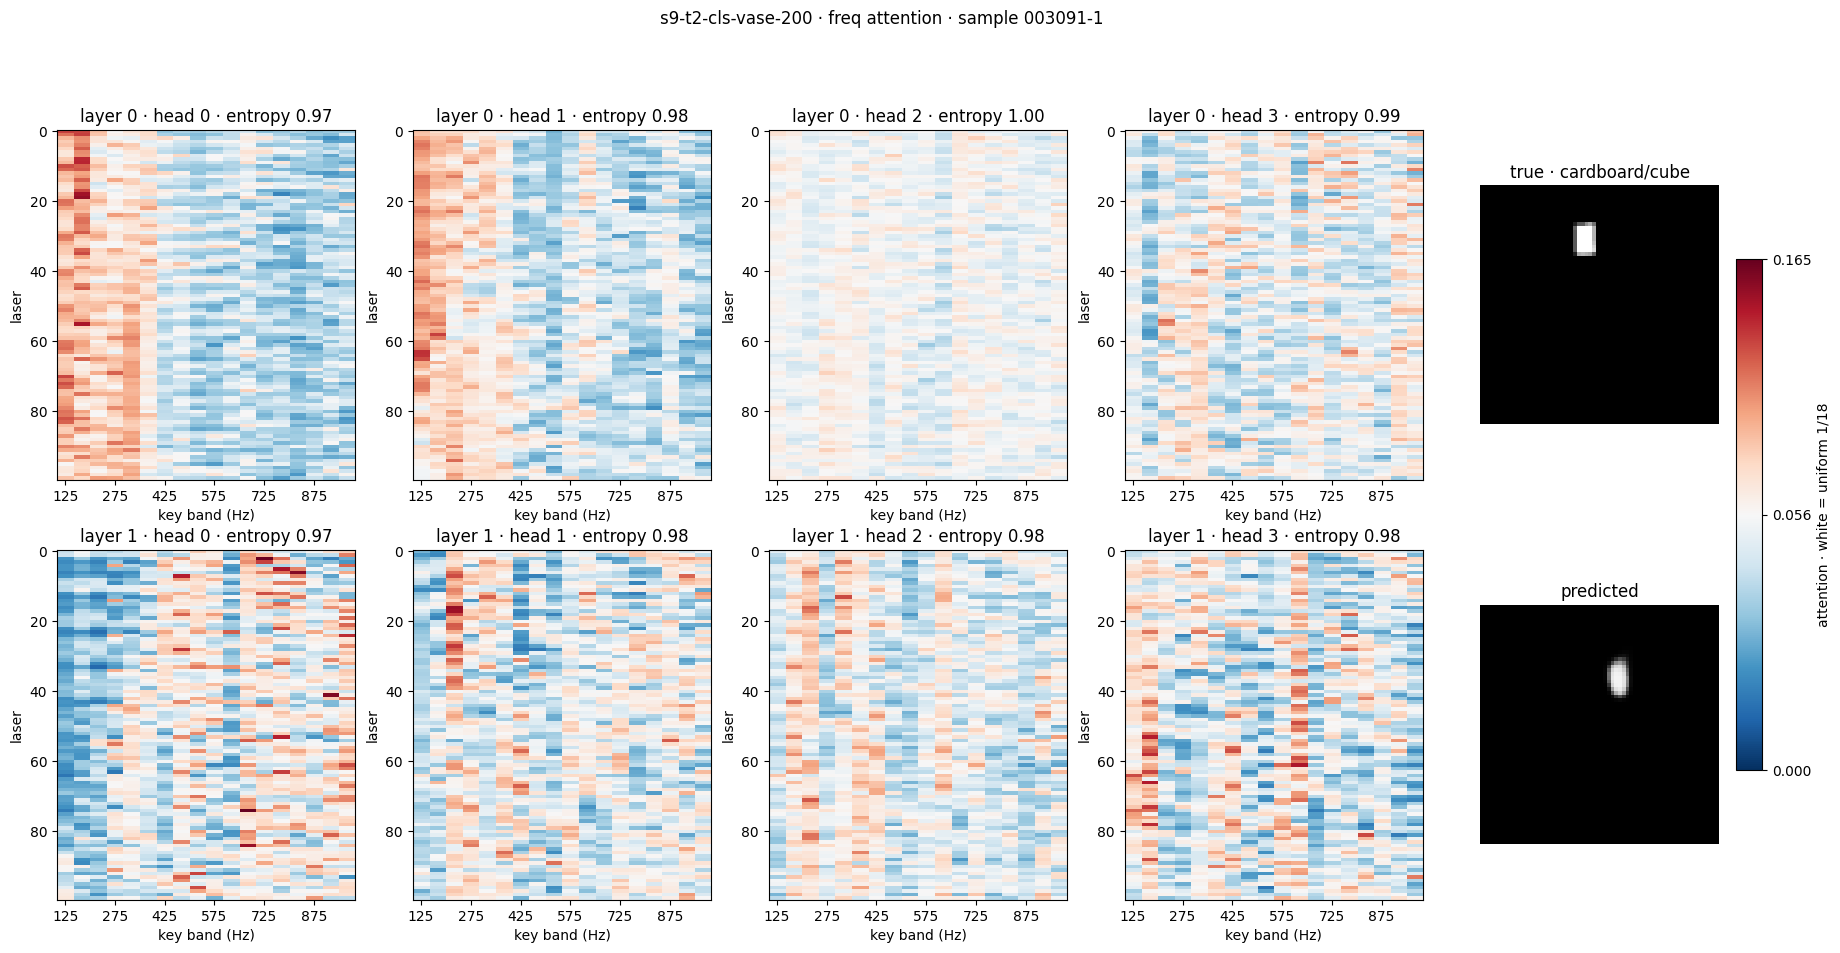

In [4]:
one = [attention_maps(b.att, 1) for b in blocks]
fig = plot([img[0].cpu() for img, _ in one], [e[0] for _, e in one], [(f"true · {split[5:]}", y_true), ("predicted", out["mask_pred"][0].cpu())])
fig.suptitle(f"{RUN} · {STAGE} attention · sample {SAMPLE}", y=1.0); plt.show()

## 2 · averaged over all eval samples
The same maps averaged over every eval sample (batches of 64). An average of maps that differ per sample can look flat,
so the honest uniformity number is the per-sample entropy, averaged (printed, and in the titles).

layer 0: per-sample normalized entropy by head (1 = uniform): 0.969 0.980 0.996 0.986
layer 1: per-sample normalized entropy by head (1 = uniform): 0.980 0.982 0.984 0.977


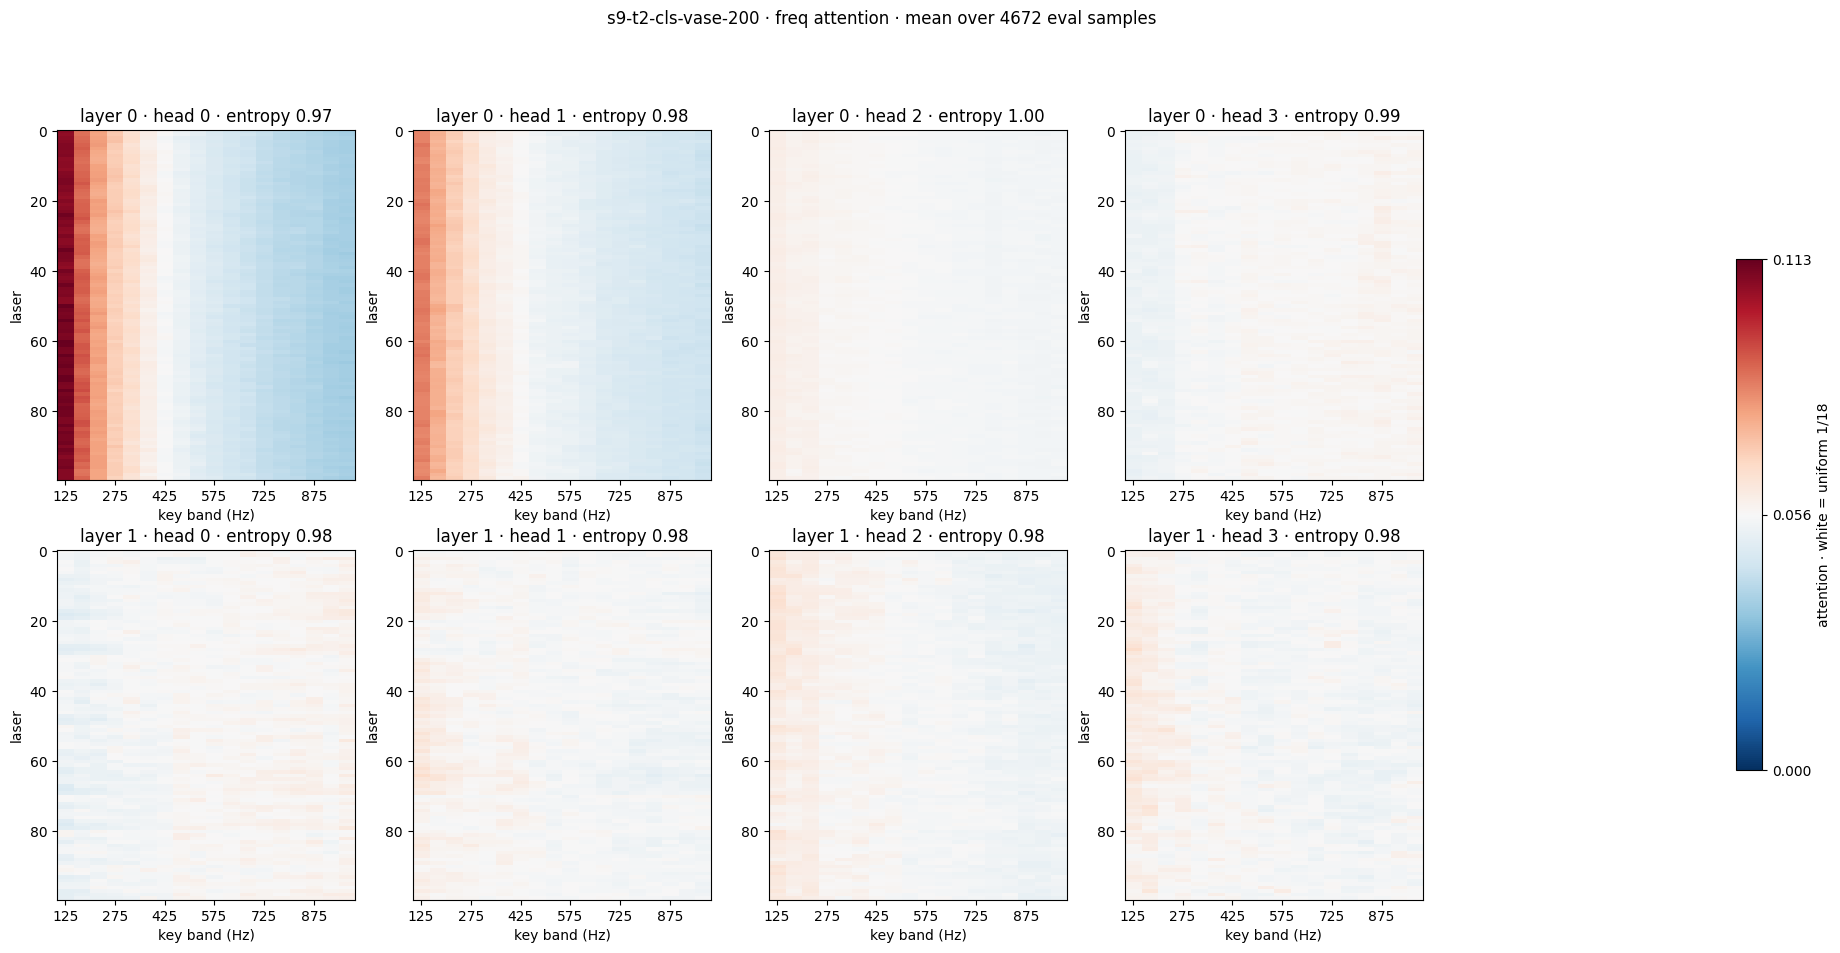

In [5]:
tot, ent = [0] * len(blocks), [0] * len(blocks)
for j in range(0, len(EVAL), 64):
    ids = EVAL[j:j + 64]
    with torch.no_grad(): model(batch(ids))
    for l, b in enumerate(blocks):
        img, e = attention_maps(b.att, len(ids))
        tot[l], ent[l] = tot[l] + img.sum(0).cpu(), ent[l] + e.sum(0).cpu()
avg, ent = [t / len(EVAL) for t in tot], [e / len(EVAL) for e in ent]
for l, e in enumerate(ent): print(f"layer {l}: per-sample normalized entropy by head (1 = uniform):", " ".join(f"{v:.3f}" for v in e.tolist()))
fig = plot(avg, ent)
fig.suptitle(f"{RUN} · {STAGE} attention · mean over {len(EVAL)} eval samples", y=1.0); plt.show()